In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

2026-02-20 00:57:51.789450: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-02-20 00:57:51.789905: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-02-20 00:57:51.856930: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-02-20 00:57:53.150950: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To tur

In [2]:
df = pd.read_csv('./data_rf2_tidy.csv')


    
# Only keep the core features that are available from the live IMIS data and the parsed snowpack profile, which are the ones we can use for real-time prediction. This also prevents issues with missing features during prediction.
core_features = [
    'TA',          # Air Temp
    'RH',          # Relative Humidity
    'VW',          # Wind Velocity
    'DW',          # Wind Direction
    'ISWR',        # Solar Radiation
    'HS_meas',     # Snow Height
    'TSG',         # Ground Temp
    'sk38_pwl',    # Skier Stability
    'sn38_pwl',    # Natural Stability
    'Sd',          # Deformation Stability
    'ccl_pwl',     # Critical Cut Length
]

top_features = [
    'HN24', 'HN72_24', 'HN24_7d',          # New snow sums (The "Memory")
    'Pen_depth', 'min_ccl_pen',             # Physical penetration depth
    'wind_trans24', 'wind_trans24_3d',      # Wind drifted snow
    'TA', 'RH', 'VW', 'DW', 'ISWR',         # Standard weather
    'pAlbedo', 'Qw',                        # Energy balance
    'MS_Snow', 'SWE',                       # Mass and Water Equivalent
    'TS1', 'TS2',                           # Internal snow temperatures
    'S4', 'Sn', 'ccl_pwl', 'sk38_pwl',      # Advanced stability indices
    'LWR_net', 'ILWR'                       # Radiation
]

# Check if they exist in the CSV, keep only those
features_to_keep = [f for f in core_features if f in df.columns]

X = df[features_to_keep]
y = df['dangerLevel']

X = X.fillna(X.median())


df.head(20)



,Unnamed: 0,datum,station_code,sector_id,dangerLevel,elevation_th,warnreg,elevation_station,set,Qs,...,ssi_pwl,sk38_pwl,sn38_pwl,ccl_pwl,ssi_pwl_100,sk38_pwl_100,sn38_pwl_100,ccl_pwl_100,Pen_depth,min_ccl_pen
0,0,2001-12-01,BER3,7112,2,2500.0,15.0,2625.0,train,6.689875,...,6.00,6.00,5.41,3.00,6.00,6.00,5.41,3.00,15.510000,4.00
1,1,2001-12-02,BED2,6111,2,2400.0,15.0,2420.0,train,14.823625,...,1.96,0.95,2.34,0.33,1.96,0.95,2.34,0.33,16.137946,0.33
2,2,2001-12-02,BER3,7112,2,2600.0,15.0,2625.0,train,35.341000,...,6.00,6.00,6.00,4.00,6.00,6.00,6.00,4.00,15.310000,4.00
3,3,2001-12-05,HTR2,5223,1,1500.0,15.0,2147.0,train,15.825250,...,1.20,0.20,4.16,0.35,1.20,0.20,4.16,0.35,16.612166,0.35
4,4,2001-12-05,HTR3,5223,1,1500.0,15.0,2200.0,train,11.049250,...,6.00,6.00,6.00,3.00,6.00,6.00,6.00,3.00,8.470000,4.00
5,5,2001-12-05,BER2,7221,1,1500.0,15.0,2447.0,train,-15.006125,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,6,2001-12-08,SPN2,4232,1,1500.0,15.0,2620.0,train,33.617250,...,6.00,6.00,6.00,3.00,6.00,6.00,6.00,3.00,7.476260,3.00
7,7,2001-12-08,SPN3,4232,1,1500.0,15.0,2424.0,train,26.791000,...,6.00,6.00,6.00,4.00,6.00,6.00,6.00,4.00,9.240000,4.00
8,8,2001-12-09,DAV3,5123,2,2400.0,15.0,2455.0,train,40.351375,...,2.05,0.05,2.14,0.39,2.05,0.05,2.14,0.39,18.831875,0.39
9,9,2001-12-09,WFJ2,5123,2,2400.0,15.0,2536.0,train,-32.176125,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:

y_encoded = tf.keras.utils.to_categorical(y - 1, num_classes=5)  # Assuming danger levels are 1-5, shift to 0-4

# Split into train/test sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42) 
# Normalize data
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Save the scaler for later use in prediction
with open('imis_scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print(f'Train set shape: {X_train_scaled.shape}, {y_train.shape}')
print(f'Test set shape: {X_test_scaled.shape}, {y_test.shape}')

Train set shape: (23436, 11), (23436, 5)
Test set shape: (5860, 11), (5860, 5)


In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.layers import Input

def build_avalanche_model(input_dim):
    
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(64, activation='relu'),
        Dropout(0.2),
        Dense(32, activation='relu'),
        Dropout(0.1),
        Dense(5, activation='softmax')
    ])
    
    model.compile(optimizer='adam', 
                  loss='categorical_crossentropy', 
                  metrics=['accuracy'])
    return model

In [9]:

model = build_avalanche_model(input_dim=X_train_scaled.shape[1])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,013 (11.77 KB)

 Trainable params: 3,013 (11.77 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
367/367 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.5369 - loss: 1.0607 - val_accuracy: 0.5838 - val_loss: 0.9404
Epoch 2/100
367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 940us/step - accuracy: 0.5836 - loss: 0.9467 - val_accuracy: 0.5964 - val_loss: 0.9166
Epoch 3/100
367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 931us/step - accuracy: 0.5896 - loss: 0.9264 - val_accuracy: 0.5980 - val_loss: 0.9075
Epoch 4/100
367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 916us/step - accuracy: 0.5925 - loss: 0.9135 - val_accuracy: 0.6012 - val_loss: 0.9005
Epoch 5/100
367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 920us/step - accuracy: 0.5975 - loss: 0.9058 - val_accuracy: 0.6056 - val_loss: 0.8930
Epoch 6/100
367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 924us/step - accuracy: 0.6032 - loss: 0.8972 - val_accuracy: 0.6072 - val_loss: 0.8895
Epoch 7/100
367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 912us/step - accuracy: 0.6076 - loss: 0.8901 - val_accuracy: 0.6096 - val_loss: 0.8805
Epoch 8/100
367/367 ━━━━━━━━━━━━━━━━━━━━ 0s 932us/step - accuracy: 0.6097 - loss: 0.8

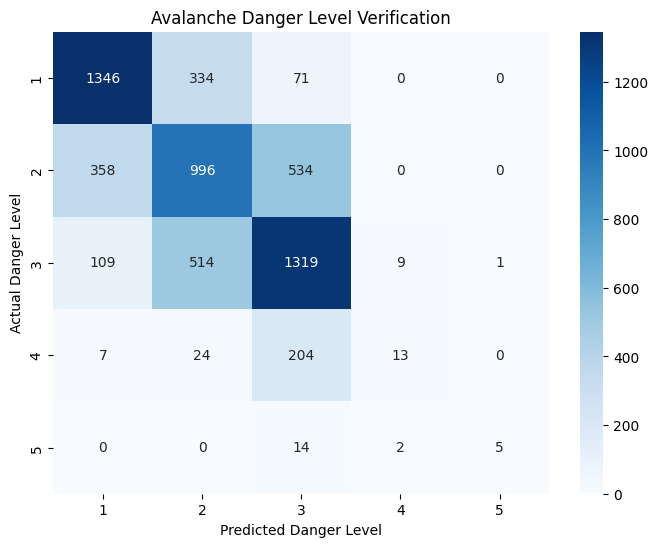

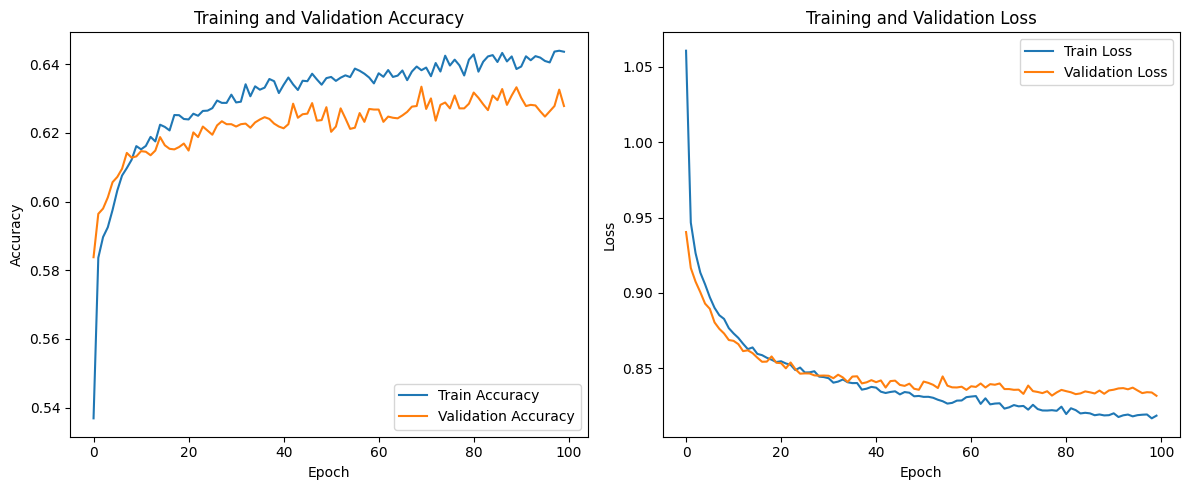

In [10]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Train the model
history = model.fit(
    X_train_scaled, y_train,
    validation_data=(X_test_scaled, y_test),
    epochs=100,
    batch_size=64,
)

# Save the trained model
model.save('avalanche_nnm2_model.keras')

# Verify with test data
y_pred_probs = model.predict(X_test_scaled)
y_pred_classes = np.argmax(y_pred_probs, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# Print Precision, Recall, and F1-Score
print(classification_report(y_true_classes, y_pred_classes, 
                            target_names=['Level 1', 'Level 2', 'Level 3', 'Level 4', 'Level 5']))

# Plot Confusion Matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=[1,2,3,4,5], yticklabels=[1,2,3,4,5])
plt.xlabel('Predicted Danger Level')
plt.ylabel('Actual Danger Level')
plt.title('Avalanche Danger Level Verification')
plt.show()

# Plot training history
plt.figure(figsize=(12,5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.tight_layout()
plt.show()
